### 1.1. RAW Audio Format and WAV Conversion

The audio recordings used in this experiment were obtained from the [dataset accompanying Jiang and Raphael (2020)](https://music.informatics.indiana.edu/papers/ismir20/data/). The recordings were provided as `.raw` files, which contain audio data without a header specifying its encoding parameters. Therefore, before processing the recordings, we needed to establish their format and convert them into standard `.wav` files.

In **Section 2.1.2 (p. 20)** of his dissertation, Jiang (2020) explicitly specifies a **sampling rate of 8 kHz**. However, the remaining encoding parameters are not documented there and had to be determined empirically. By inspecting several RAW files, analyzing the decoded samples, and listening to candidate WAV recordings, we established the following format:

- **Sampling rate:** 8,000 Hz (specified in the dissertation)
- **Channels:** Mono
- **Sample format:** Signed 16-bit PCM
- **Byte order:** Little-endian

Using these parameters, all 50 RAW recordings were converted into WAV files. This conversion preserved the original PCM samples without resampling or modifying the audio signal.

In [1]:
from pathlib import Path
import sys
from IPython.display import Audio, display

project_root = Path.cwd()

sys.path.insert(0, str(project_root / "audio-preparation"))
from convert_raw_to_wav import convert_one

raw_path = project_root / "audio" / "franz_standchen.000.raw"

# Save the converted WAV separately for this demonstration
wav_path = project_root / "audio" / "notebook_preview" / f"{raw_path.stem}.wav"
wav_path.parent.mkdir(parents=True, exist_ok=True)

# Convert using our existing module
result = convert_one(raw_path, wav_path, overwrite=False)
print(f"Conversion: {result}")

# Display an embedded audio player
display(Audio(filename=str(wav_path)))

Conversion: converted (102.00 s)


### 1.2. Audio Framing

After converting the RAW recordings into WAV format, the next step is to decode each recording into a numerical array of audio samples. Each sample represents the amplitude of the recorded sound wave at a particular instant. However, individual samples provide little information about the musical content of a recording. To analyze how the sound changes over time, we divide the sample sequence into short, overlapping segments called **audio frames**.

In **Section 2.1.2 (p. 20)** of his dissertation, Jiang (2020) describes the framing procedure using a sampling rate of **8,000 Hz** and a frame length of **512 samples**, corresponding to 64 milliseconds of audio. For the tempo-tracking experiment, **Section 5.3 (p. 74)** specifies a hop size of **128 samples**, giving the following parameters:

- **Sampling rate:** 8,000 Hz
- **Frame length:** 512 samples (64 ms)
- **Hop size:** 128 samples (16 ms)
- **Overlap:** 384 samples (75%)

The hop size determines how far we advance through the recording before extracting the next frame. Since the hop is smaller than the frame length, consecutive frames share part of the same audio signal. This allows the algorithm to obtain a new observation every 16 milliseconds while analyzing 64 milliseconds of audio at a time.

In our implementation, the frames are organized into a two-dimensional NumPy array, where each row contains 512 consecutive samples. Each frame is also assigned an index and a timestamp corresponding to its starting position in the recording. Only complete frames are retained; any remaining samples at the end of a recording are left unused.

These frames will serve as the input to the short-time Fourier transform in the next stage of audio preparation.

In [3]:
from frame_audio import load_samples, create_frames

# Load the WAV recording used in the previous step
samples = load_samples(wav_path)

print(f"Total samples: {len(samples):,}")
print(f"Sample array shape: {samples.shape}")
print(f"First 10 samples: {samples[:10]}")

# Divide the audio into overlapping frames
frames, frame_indices, start_samples, timestamps = create_frames(samples)

print(f"\nFrames array shape: {frames.shape}")
print(f"Total frames: {len(frames):,}")
print(f"First 10 samples of frame 0: {frames[0, :10]}")

# Inspect the positions of the first three frames
print("\nFirst three frames:")
for i in range(3):
    print(
        f"Frame {frame_indices[i]}: "
        f"samples {start_samples[i]}–{start_samples[i] + 511}, "
        f"start time = {timestamps[i]:.3f} s"
    )


Total samples: 816,000
Sample array shape: (816000,)
First 10 samples: [ 59  96  78  71  87  95  84  73  92 120]

Frames array shape: (6372, 512)
Total frames: 6,372
First 10 samples of frame 0: [ 59  96  78  71  87  95  84  73  92 120]

First three frames:
Frame 0: samples 0–511, start time = 0.000 s
Frame 1: samples 128–639, start time = 0.016 s
Frame 2: samples 256–767, start time = 0.032 s


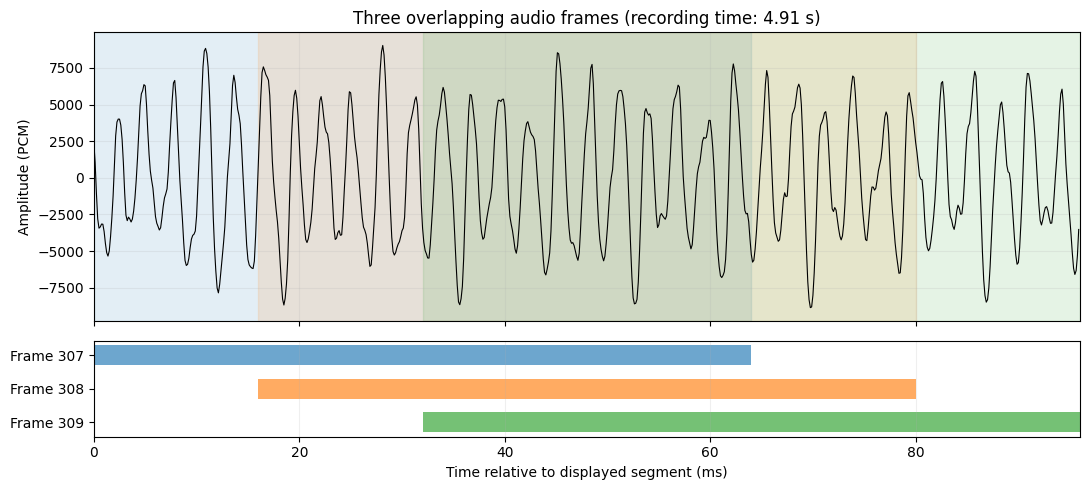

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from frame_audio import SAMPLE_RATE, HOP_SIZE

# Select three consecutive frames from an active part of the recording
num_display = 3
search_limit = min(len(frames) - num_display + 1,
                   5 * SAMPLE_RATE // HOP_SIZE)

frame_energy = np.mean(
    frames[:search_limit].astype(np.float64) ** 2, axis=1
)
first_frame = int(np.argmax(frame_energy))

# Determine the sample range containing all three frames
frame_length = frames.shape[1]
start = int(start_samples[first_frame])
end = int(start_samples[first_frame + 2] + frame_length)

# Time axis relative to the beginning of the displayed segment (ms)
time_ms = np.arange(end - start) / SAMPLE_RATE * 1000
frame_duration_ms = frame_length / SAMPLE_RATE * 1000

# Create the visualization
fig, (ax_wave, ax_frames) = plt.subplots(
    2, 1, figsize=(11, 5), sharex=True,
    gridspec_kw={"height_ratios": [3, 1]}
)

ax_wave.plot(time_ms, samples[start:end],
             color="black", linewidth=0.8)

colors = ["tab:blue", "tab:orange", "tab:green"]

for i, color in enumerate(colors):
    frame_idx = first_frame + i
    left_ms = (start_samples[frame_idx] - start) / SAMPLE_RATE * 1000

    # Highlight the frame's interval on the waveform
    ax_wave.axvspan(left_ms, left_ms + frame_duration_ms,
                    color=color, alpha=0.12)

    # Show the frame as a horizontal bar
    ax_frames.barh(2 - i, frame_duration_ms, left=left_ms,
                   height=0.6, color=color, alpha=0.65)

ax_wave.set_title(
    f"Three overlapping audio frames "
    f"(recording time: {start / SAMPLE_RATE:.2f} s)"
)
ax_wave.set_ylabel("Amplitude (PCM)")
ax_wave.grid(alpha=0.2)

ax_frames.set_yticks(
    [2, 1, 0],
    [f"Frame {first_frame + i}" for i in range(num_display)]
)
ax_frames.set_xlim(0, (end - start) / SAMPLE_RATE * 1000)
ax_frames.set_xlabel("Time relative to displayed segment (ms)")
ax_frames.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

### 1.3. Fourier Transform and Spectral Normalization

Following **Section 2.1.3 (pp. 20–21)** of Jiang's dissertation (2020), we apply the **Short-Time Fourier Transform (STFT)** to represent each audio frame in the frequency domain. For each frame of 512 samples, Jiang defines the windowed Discrete Fourier Transform (DFT) as:

$$
X_w = \sum_{t=1}^{T} h(t)\,x_t\,e^{-i\frac{2\pi}{T}(w-1)(t-1)}
$$

where $x_t$ is the sample amplitude, $h(t)$ is the window function, and $X_w$ is the complex Fourier coefficient.

Since Jiang does not specify the window type, we use a **periodic Hann window** to reduce spectral leakage. We compute the DFT using NumPy's `numpy.fft.rfft()`, which efficiently calculates Fourier coefficients for real-valued signals using an FFT algorithm.

Following Jiang, we retain the magnitudes of the first **256 frequency coefficients** and normalize them:

$$
y'_w = \frac{|X_w|}{\sum_{j=1}^{256}|X_j|}
$$

This makes each nonzero spectrum sum to 1, reducing the influence of overall signal amplitude. Completely silent frames are represented by zero vectors in our implementation.

The final output is a two-dimensional NumPy array containing **256 normalized frequency magnitudes per frame**, stored alongside frame indices and timestamps.

In [5]:
from extract_audio_features import (
    apply_window,
    compute_spectra,
    normalize_spectra
)

# Select the same frame used in the previous visualization
selected_frame = frames[first_frame:first_frame + 1]

# Apply each stage of our feature extraction pipeline
windowed = apply_window(selected_frame)
spectra = compute_spectra(windowed)
normalized = normalize_spectra(spectra)

# Inspect the resulting arrays
print(f"Original frame shape:    {selected_frame.shape}")
print(f"Windowed frame shape:    {windowed.shape}")
print(f"Magnitude spectrum shape: {spectra.shape}")
print(f"Normalized spectrum shape: {normalized.shape}")

print("\nFirst 10 spectral magnitudes:")
print(spectra[0, :10])

print("\nFirst 10 normalized magnitudes:")
print(normalized[0, :10])

# Verify normalization
print(f"\nSum before normalization: {spectra[0].sum():.4f}")
print(f"Sum after normalization:  {normalized[0].sum():.4f}")


Original frame shape:    (1, 512)
Windowed frame shape:    (1, 512)
Magnitude spectrum shape: (1, 256)
Normalized spectrum shape: (1, 256)

First 10 spectral magnitudes:
[ 1341.05765162   761.67661994   820.16133622  9171.1539269
 16082.89994877 13487.28329261  6326.31753476 57371.22576229
 57987.55885259 14514.54536342]

First 10 normalized magnitudes:
[0.0003591  0.00020396 0.00021962 0.00245582 0.00430662 0.00361157
 0.00169404 0.01536265 0.01552769 0.00388665]

Sum before normalization: 3734461.9054
Sum after normalization:  1.0000


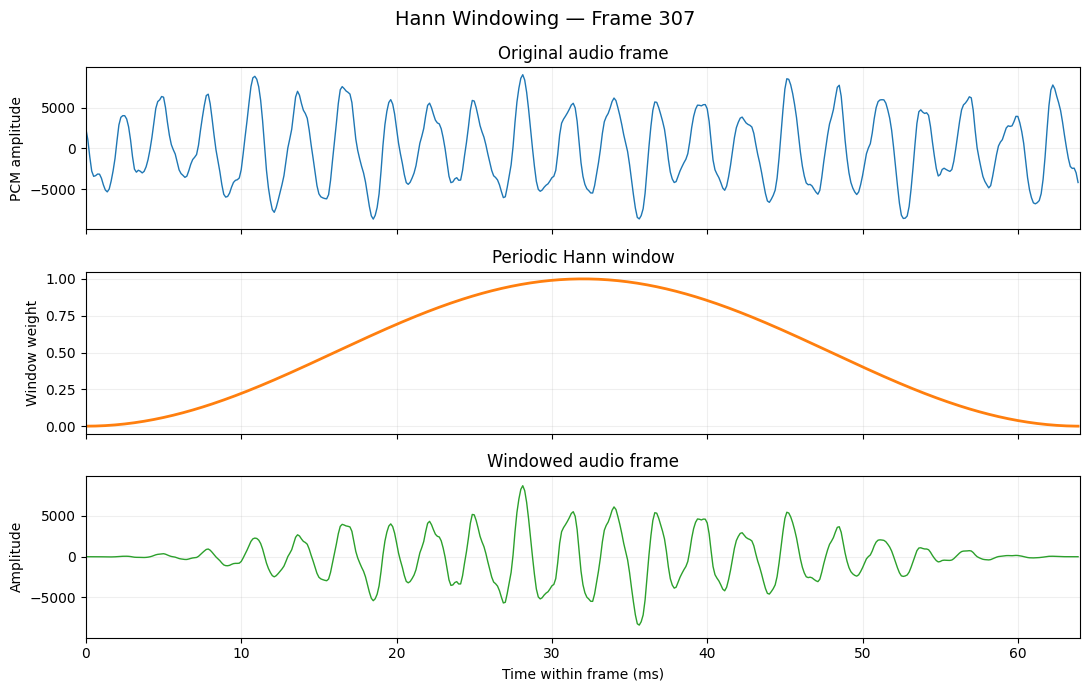

In [7]:
from extract_audio_features import make_window
from frame_audio import SAMPLE_RATE

# Use the same frame and windowed signal from the previous cell
original = selected_frame[0]
window = make_window()
windowed_signal = windowed[0]

# Time axis in milliseconds
time_ms = np.arange(len(original)) / SAMPLE_RATE * 1000

# Create three vertically stacked plots
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)

# Original waveform
axes[0].plot(time_ms, original, color="tab:blue", linewidth=1)
axes[0].set_title("Original audio frame")
axes[0].set_ylabel("PCM amplitude")
axes[0].grid(alpha=0.2)

# Hann window
axes[1].plot(time_ms, window, color="tab:orange", linewidth=2)
axes[1].set_title("Periodic Hann window")
axes[1].set_ylabel("Window weight")
axes[1].set_ylim(-0.05, 1.05)
axes[1].grid(alpha=0.2)

# Windowed waveform
axes[2].plot(time_ms, windowed_signal, color="tab:green", linewidth=1)
axes[2].set_title("Windowed audio frame")
axes[2].set_ylabel("Amplitude")
axes[2].set_xlabel("Time within frame (ms)")
axes[2].grid(alpha=0.2)

# Use the same amplitude scale for both waveforms
amplitude_limit = max(1, np.max(np.abs(original)) * 1.1)
axes[0].set_ylim(-amplitude_limit, amplitude_limit)
axes[2].set_ylim(-amplitude_limit, amplitude_limit)

axes[2].set_xlim(0, 64)

fig.suptitle(f"Hann Windowing — Frame {first_frame}", fontsize=14)
plt.tight_layout()
plt.show()


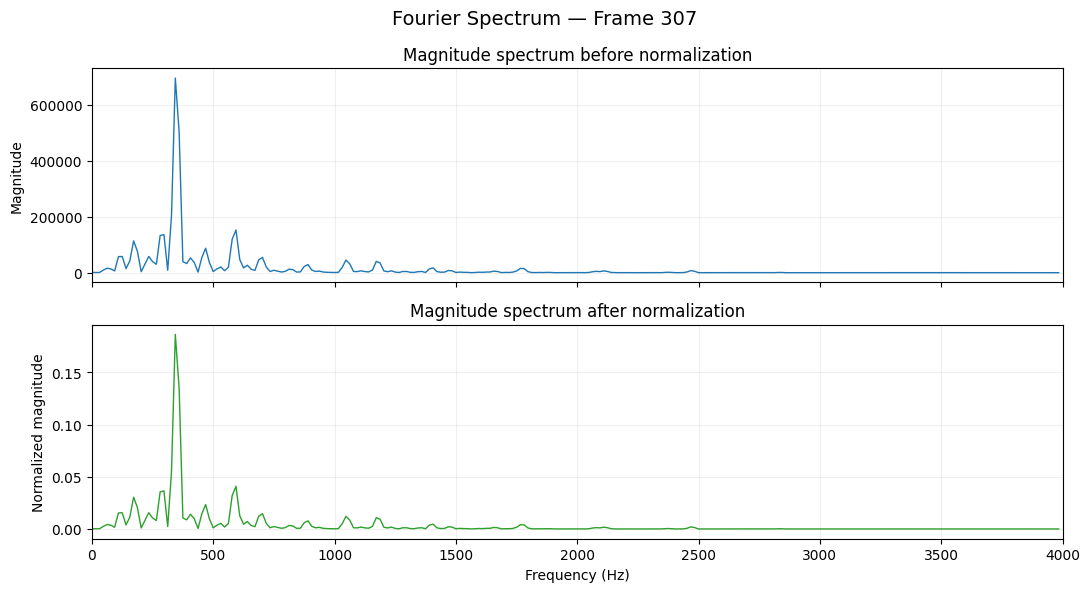

Frequency resolution: 15.625 Hz
Number of frequency bins: 256
Sum before normalization: 3734461.9054
Sum after normalization:  1.0000


In [8]:
from frame_audio import SAMPLE_RATE, FRAME_LENGTH

magnitudes = spectra[0]
normalized_magnitudes = normalized[0]

# Calculate the frequency corresponding to each of the 256 bins
frequencies = np.fft.rfftfreq(
    FRAME_LENGTH, d=1 / SAMPLE_RATE
)[:256]

# Create two vertically stacked plots
fig, axes = plt.subplots(
    2, 1, figsize=(11, 6), sharex=True
)

# Original magnitude spectrum
axes[0].plot(
    frequencies, magnitudes,
    color="tab:blue", linewidth=1
)
axes[0].set_title("Magnitude spectrum before normalization")
axes[0].set_ylabel("Magnitude")
axes[0].grid(alpha=0.2)

# Normalized magnitude spectrum
axes[1].plot(
    frequencies, normalized_magnitudes,
    color="tab:green", linewidth=1
)
axes[1].set_title("Magnitude spectrum after normalization")
axes[1].set_ylabel("Normalized magnitude")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].grid(alpha=0.2)

# Display the complete frequency range
axes[1].set_xlim(0, 4000)

fig.suptitle(
    f"Fourier Spectrum — Frame {first_frame}",
    fontsize=14
)
plt.tight_layout()
plt.show()

# Verify the normalization
print(f"Frequency resolution: {SAMPLE_RATE / FRAME_LENGTH:.3f} Hz")
print(f"Number of frequency bins: {len(frequencies)}")
print(f"Sum before normalization: {magnitudes.sum():.4f}")
print(f"Sum after normalization:  {normalized_magnitudes.sum():.4f}")
